# 04. Feature Engineering

**Proyek akhir Jaringan Saraf Tiruan: MLP dengan backpropagation**

Notebook ini menguji apakah fitur turunan (feature engineering) dapat menurunkan error MLP. Pengaturan lain dibuat sama persis dengan kandidat notebook 03 agar perbedaan hanya berasal dari fitur:

- **Kontrol:** kandidat notebook 03 (67 input, hidden [8] sigmoid, MSE loss, gradient descent dengan learning rate 0,1).
- **Varian:** kontrol ditambah fitur turunan.

Empat varian di-screening dengan seed 42, lalu varian terbaik dibandingkan dengan kontrol pada tiga seed. **Test tidak disentuh.**

## 1. Aturan keputusan (ditetapkan sebelum training)

Varian feature engineering dipromosikan hanya jika:

1. Rerata validation MAE membaik minimal **0,01 poin SOH**, dan
2. Menang minimal di 2 dari 3 seed.

Aturan ini ditetapkan sebelum melihat hasil, sehingga keputusan tidak bisa disesuaikan belakangan. Ke-67 fitur lama dipertahankan persis, dan fitur baru ditambahkan di belakangnya.

In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Image

REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()), None)
if REPO is None:
    raise RuntimeError("Buka dari root proyek atau folder notebooks.")
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))
from ev_battery.paths import prepare_workspace

ROOT = prepare_workspace(REPO)
from ev_battery.features import (
    run_feature_study,
    load_engineered_data,
    load_raw_observations,
    pipeline_state_fingerprint,
)
from ev_battery.reporting.features import build_report, read_results
from ev_battery.training import (
    load_training_data,
    load_checkpoint,
    original_scale,
    configure_runtime,
)

pd.set_option("display.max_columns", 14)
pd.set_option("display.precision", 6)
settings = json.loads((ROOT / "configs/feature_engineering.json").read_text(encoding="utf-8"))
configure_runtime(42)
display(pd.Series(settings, name="protokol").to_frame())

,protokol
schema_version,1
reference_candidate_run_id,run_0015e8ebf51d
base_recipe,baseline_standard
screening_seed,42
confirmation_seeds,"[42, 123, 2026]"
variants,"{'fe_usage_rates': ['usage_rates'], 'fe_contex..."
clip_quantiles,"[0.005, 0.995]"
minimum_mean_mae_improvement_pp,0.01
minimum_seed_wins,2
decision_note,Provisional promotion only if confirmation mea...


## 2. Menjalankan study

Pipeline tambahan di-fit hanya pada train. Data dibaca tanpa kolom target, dan baris test dibuang sebelum perhitungan apa pun. Training memakai `bp_fit` NumPy yang sama dengan notebook 03, dan run yang identik dipakai ulang dari cache.

In [2]:
study = run_feature_study(ROOT)
report = build_report(ROOT)
output, study, tables = read_results(ROOT)
best = study["selected_engineered_variant"]
control = load_training_data(settings["base_recipe"], ROOT)
raw = load_raw_observations(control, ROOT)
full = load_engineered_data("fe_combined", ROOT)
prep = full["bundle"]["preprocessor"]


def show(name):
    display(Image(filename=str(output / name), width=1100))


assert study["test_arrays_loaded"] is False and study["test_transformed"] is False
print("Run baru dalam versi final:", study["new_training_runs"])
print("Varian FE terbaik (screening):", best, "| rekomendasi:", study["recommendation"])

FEATURE STUDY: best=fe_context, mean gain=0.00286 pp, wins=2/3, recommendation=control_no_domain_features


Run baru dalam versi final: 6
Varian FE terbaik (screening): fe_context | rekomendasi: control_no_domain_features


## 3. Definisi fitur turunan

| Blok | Fitur | Makna |
|---|---|---|
| Rasio pemakaian | `cycle_count / battery_age_days`, `total_energy_throughput_kwh / cycle_count` | Intensitas pemakaian per hari dan energi per siklus |
| Konteks pengisian | `peak_temp - ambient_temp`, `fast_charge_ratio × DOD` | Kenaikan suhu saat fast charge dan interaksi fast charge dengan kedalaman discharge |
| Interaksi kimia | indikator kimia × `log1p(siklus)` dan × `log1p(umur dalam tahun)` | Laju degradasi yang berbeda per kimia (8 fitur) |

Fitur ini tidak menambah informasi pengukuran baru. Fitur tersebut hanya membuat pola tertentu lebih eksplisit bagi jaringan.

In [3]:
display(pd.read_csv(output / "feature_definitions.csv"))
arithmetic = prep._arithmetic(raw["train"])
display(arithmetic.head())
assert len(prep.extra_columns_) == 12
assert "state_of_health_pct" not in prep.required_columns
assert "capacity_fade_pct" not in prep.required_columns

,block,feature,formula,unit
0,usage_rates,fe_cycles_per_day,cycle_count / battery_age_days,"cycles/day, snapshot ratio"
1,usage_rates,fe_energy_per_cycle_kwh,total_energy_throughput_kwh / cycle_count,kWh/cycle
2,context,fe_charge_ambient_delta_c,peak_temp_during_fast_charge_c - avg_ambient_t...,°C
3,context,fe_fastcharge_dod_interaction,fast_charge_ratio * avg_depth_of_discharge_pct...,ratio interaction
4,chemistry,fe_chem_<chemistry>_log_cycles,I(chemistry=c) * log1p(cycle_count),"interaction, 4 columns from train chemistries"
5,chemistry,fe_chem_<chemistry>_log_age_years,I(chemistry=c) * log1p(battery_age_days / 365.25),"interaction, 4 columns from train chemistries"


,fe_cycles_per_day,fe_energy_per_cycle_kwh,fe_charge_ambient_delta_c,fe_fastcharge_dod_interaction,fe_chem_LFP_log_cycles,fe_chem_LMO_log_cycles,fe_chem_NCA_log_cycles,fe_chem_NMC_log_cycles,fe_chem_LFP_log_age_years,fe_chem_LMO_log_age_years,fe_chem_NCA_log_age_years,fe_chem_NMC_log_age_years
0,NaN,70.834644,9.0,0.457033,6.011267,0.0,0.000000,0.0,NaN,NaN,NaN,NaN
1,0.623077,83.074383,6.9,0.315150,0.000000,0.0,5.783825,0.0,0.0,0.0,0.885288,0.0
2,1.569288,63.977685,2.6,NaN,0.000000,0.0,6.732211,0.0,0.0,0.0,0.900979,0.0
3,1.017699,39.892174,8.9,0.366388,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.448276,NaN,6.8,0.203808,0.000000,0.0,3.295837,0.0,0.0,0.0,0.147381,0.0


## 4. Pembagian dengan nol dan missing value

Rasio hanya dihitung jika kedua operand tersedia dan pembaginya lebih dari nol. Jika tidak, hasilnya missing dan ditandai oleh indikator. Kimia yang tidak dikenal juga menghasilkan missing, bukan dipaksa menjadi salah satu kimia yang ada.

In [4]:
probe = raw["train"].iloc[:2].copy()
probe.loc[probe.index[0], "battery_age_days"] = 0.0
probe.loc[probe.index[1], "chemistry"] = "NEW_CHEMISTRY_PROBE"
computed = prep._arithmetic(probe)
assert pd.isna(computed.iloc[0]["fe_cycles_per_day"])
chem_columns = [c for c in prep.extra_columns_ if c.startswith("fe_chem_")]
assert computed.iloc[1][chem_columns].isna().all()
assert np.isfinite(prep.transform(probe)).all()
print("PASS: denominator nol dan kimia baru ditangani tanpa angka buatan.")

PASS: denominator nol dan kimia baru ditangani tanpa angka buatan.


## 5. Fit pada train dan kontrol tetap identik

Median, batas capping, dan scaler untuk fitur baru dipelajari dari train. Sel berikut memastikan 67 kolom pertama sama persis (bit-for-bit) dengan input kontrol, sehingga perbedaan hasil hanya berasal dari fitur tambahan.

In [5]:
before = joblib.hash(prep)
for split in ["train", "validation"]:
    engineered = full[split]["X"]
    base = control[split]["X"]
    np.testing.assert_array_equal(engineered[:, : base.shape[1]], base)
    np.testing.assert_array_equal(full[split]["y_original"], control[split]["y_original"])
    np.testing.assert_array_equal(full[split]["observation_id"], control[split]["observation_id"])
assert joblib.hash(prep) == before
assert prep.fit_rows_ == 34929
assert full["bundle"]["target_scaler"].mean_[0] == control["bundle"]["target_scaler"].mean_[0]
display(pd.read_csv(output / "train_feature_diagnostics.csv"))
print(
    "PASS: 67 kolom dasar, target, dan urutan observasi sama. Parameter tambahan tidak berubah saat transform."
)

,feature,missing_train,missing_train_pct,median_train_before_log,cap_low_train,cap_high_train,signed_log1p_after_cap,scaler_mean_train,scaler_scale_train,raw_min_train,raw_max_train,spearman_target_train
0,fe_cycles_per_day,3625,10.378196,0.935903,0.253252,2.396034,True,0.672961,0.220331,0.142857,2.710665,-0.278663
1,fe_energy_per_cycle_kwh,3865,11.065304,67.059492,36.937265,96.952114,True,4.203296,0.198826,34.428664,99.742857,-0.000459
2,fe_charge_ambient_delta_c,3674,10.518480,5.000000,-12.640170,23.600000,False,5.502067,4.542165,-43.036622,61.324838,-0.005398
3,fe_fastcharge_dod_interaction,4225,12.095966,0.168310,NaN,NaN,False,0.187001,0.115225,0.000000,0.830169,-0.006008
4,fe_chem_LFP_log_cycles,3894,11.148329,0.000000,NaN,NaN,False,1.517927,2.602577,0.000000,8.424200,0.203420
5,fe_chem_LMO_log_cycles,3894,11.148329,0.000000,NaN,NaN,False,0.753717,1.992720,0.000000,8.374246,-0.205640
6,fe_chem_NCA_log_cycles,3894,11.148329,0.000000,NaN,NaN,False,1.108994,2.353396,0.000000,8.456168,-0.184677
7,fe_chem_NMC_log_cycles,3894,11.148329,0.000000,NaN,NaN,False,1.684897,2.692985,0.000000,8.531885,-0.175285
8,fe_chem_LFP_log_age_years,4361,12.485327,0.000000,NaN,NaN,False,0.211036,0.433362,0.000000,1.923564,0.205326
9,fe_chem_LMO_log_age_years,4361,12.485327,0.000000,NaN,NaN,False,0.103162,0.319233,0.000000,1.926360,-0.208063


PASS: 67 kolom dasar, target, dan urutan observasi sama. Parameter tambahan tidak berubah saat transform.


## 6. Screening empat varian (seed 42)

| Varian | Input neuron |
|---|---:|
| Kontrol | 67 |
| Rasio pemakaian | 71 |
| Konteks pengisian | 71 |
| Interaksi kimia | 83 |
| Gabungan | 91 |

Hidden layer tetap [8], tetapi jumlah parameter bertambah seiring jumlah input.

,variant,run_id,seed,input_neurons,parameters,train_mae_pp,validation_mae_pp,validation_rmse_pp,validation_r2,best_epoch,epochs_actual
0,control_no_domain_features,run_0015e8ebf51d,42,67,553,0.962886,0.994276,1.503874,0.954102,96,105
1,fe_usage_rates,run_c3f70c44f506,42,71,585,0.978042,1.003860,1.519494,0.953143,27,42
2,fe_context,run_2297ec26d5df,42,71,585,0.969770,0.998749,1.509009,0.953788,62,77
3,fe_chemistry,run_10b2a2751fe1,42,83,681,0.994453,1.020630,1.532234,0.952354,27,42
4,fe_combined,run_7875bbe5a00b,42,91,745,0.988901,1.027859,1.534155,0.952235,41,42


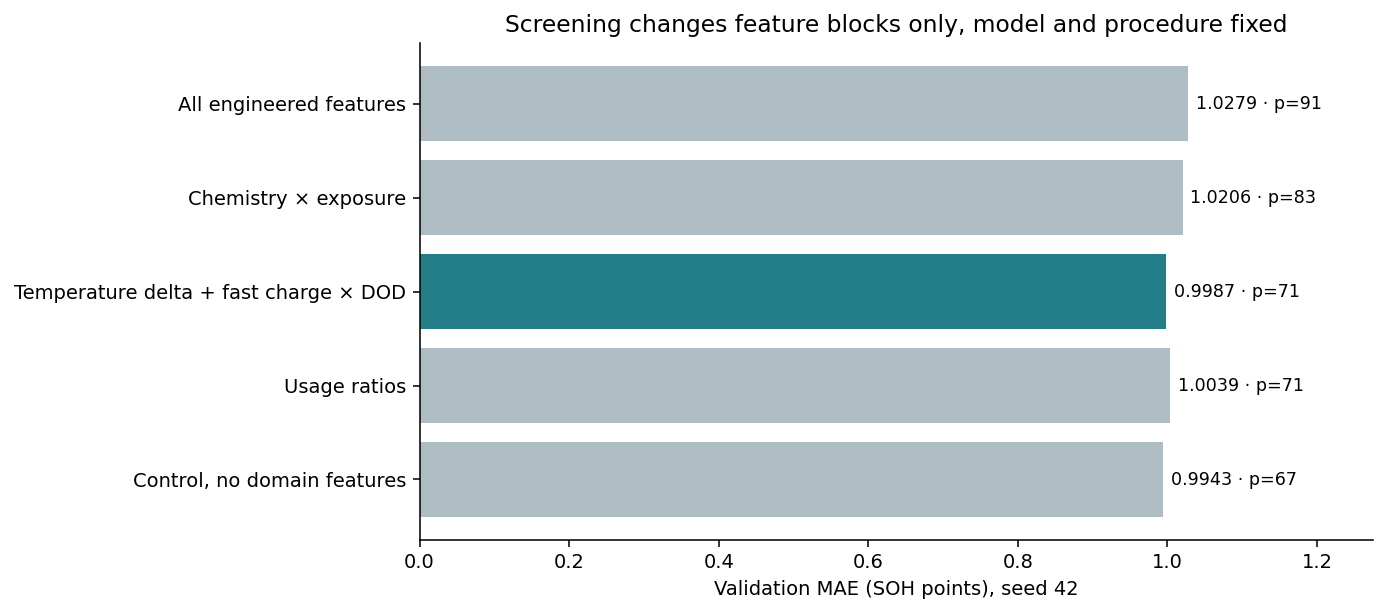

In [6]:
display(tables["screening"])
show("01_feature_screening.png")
assert len(tables["screening"]) == 5
assert tables["screening"].input_neurons.tolist() == [67, 71, 71, 83, 91]

**Temuan:** pada seed 42, **tidak ada varian yang mengalahkan kontrol** (0,9943). Varian terbaik adalah konteks pengisian (0,9987), disusul rasio pemakaian (1,0039), interaksi kimia (1,0206), dan gabungan (1,0279). Semakin banyak fitur yang ditambahkan, hasilnya justru semakin buruk. Sesuai protokol, varian terbaik (konteks pengisian) tetap dikonfirmasi dengan tiga seed.

## 7. Konfirmasi tiga seed

Kontrol dan varian konteks pengisian dilatih dengan seed 42, 123, dan 2026 menggunakan arsitektur dan prosedur yang sama.

,variant,run_id,seed,input_neurons,parameters,train_mae_pp,validation_mae_pp,validation_rmse_pp,validation_r2,best_epoch,epochs_actual
0,control_no_domain_features,run_0015e8ebf51d,42,67,553,0.962886,0.994276,1.503874,0.954102,96,105
1,control_no_domain_features,run_17e82e31806b,123,67,553,0.974880,1.009424,1.513992,0.953482,56,56
2,control_no_domain_features,run_125d105f67b2,2026,67,553,0.970477,0.995940,1.491977,0.954825,58,58
3,fe_context,run_2297ec26d5df,42,71,585,0.969770,0.998749,1.509009,0.953788,62,77
4,fe_context,run_cc4cc71fe6e3,123,71,585,0.968597,1.001173,1.508371,0.953827,62,77
5,fe_context,run_8b95561602e7,2026,71,585,0.964648,0.991149,1.496463,0.954553,34,49


,variant,n_seeds,mae_mean_pp,mae_sd_pp,rmse_mean_pp,r2_mean,parameters
0,control_no_domain_features,3,0.999880,0.008307,1.503281,0.954136,553
1,fe_context,3,0.997024,0.005230,1.504614,0.954056,585


,seed,control_no_domain_features,fe_context,mae_improvement_pp
0,42,0.994276,0.998749,-0.004473
1,123,1.009424,1.001173,0.008251
2,2026,0.995940,0.991149,0.004791


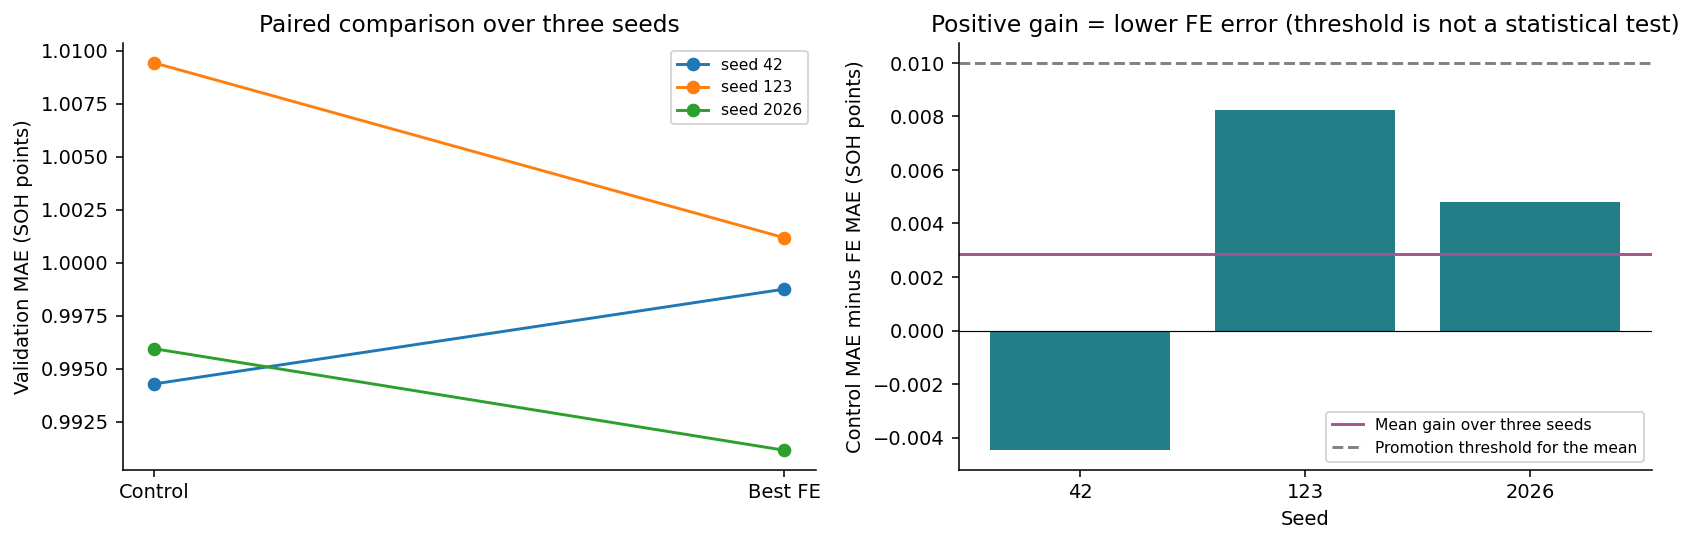

Gain rerata (poin SOH): 0.0028561674449459895


In [7]:
display(tables["seed_confirmation"])
display(tables["seed_summary"])
display(tables["paired_seed_improvements"])
show("02_paired_seed_improvements.png")
summary = tables["seed_summary"].set_index("variant")
paired = tables["paired_seed_improvements"]
assert np.isclose(paired.mae_improvement_pp.mean(), study["mean_validation_mae_improvement_pp"])
assert paired.mae_improvement_pp.gt(0).sum() == study["seed_wins"]
print("Gain rerata (poin SOH):", study["mean_validation_mae_improvement_pp"])

**Temuan:** rerata MAE kontrol **0,99988 ± 0,00831** dan varian konteks pengisian **0,99702 ± 0,00523** poin SOH. Gain-nya hanya **0,00286 poin** (0,29% dari error kontrol). Varian ini menang di seed 123 dan 2026, tetapi kalah di seed 42. Selisih sekecil ini masih dalam batas variasi antar-seed.

## 8. Error per rentang SOH

,variant,band,n_rows,batteries,mae_mean_pp,mae_sd_pp
0,control_no_domain_features,<70,106,28,3.511278,0.088344
1,control_no_domain_features,70–<80,338,80,2.172848,0.055532
2,control_no_domain_features,80–<90,1390,218,1.336457,0.023552
3,control_no_domain_features,90–<95,1814,305,0.987648,0.017824
4,control_no_domain_features,>=95,3851,384,0.712078,0.003842
5,fe_context,<70,106,28,3.411486,0.282168
6,fe_context,70–<80,338,80,2.158648,0.029559
7,fe_context,80–<90,1390,218,1.325645,0.004307
8,fe_context,90–<95,1814,305,0.996030,0.004187
9,fe_context,>=95,3851,384,0.710464,0.004924


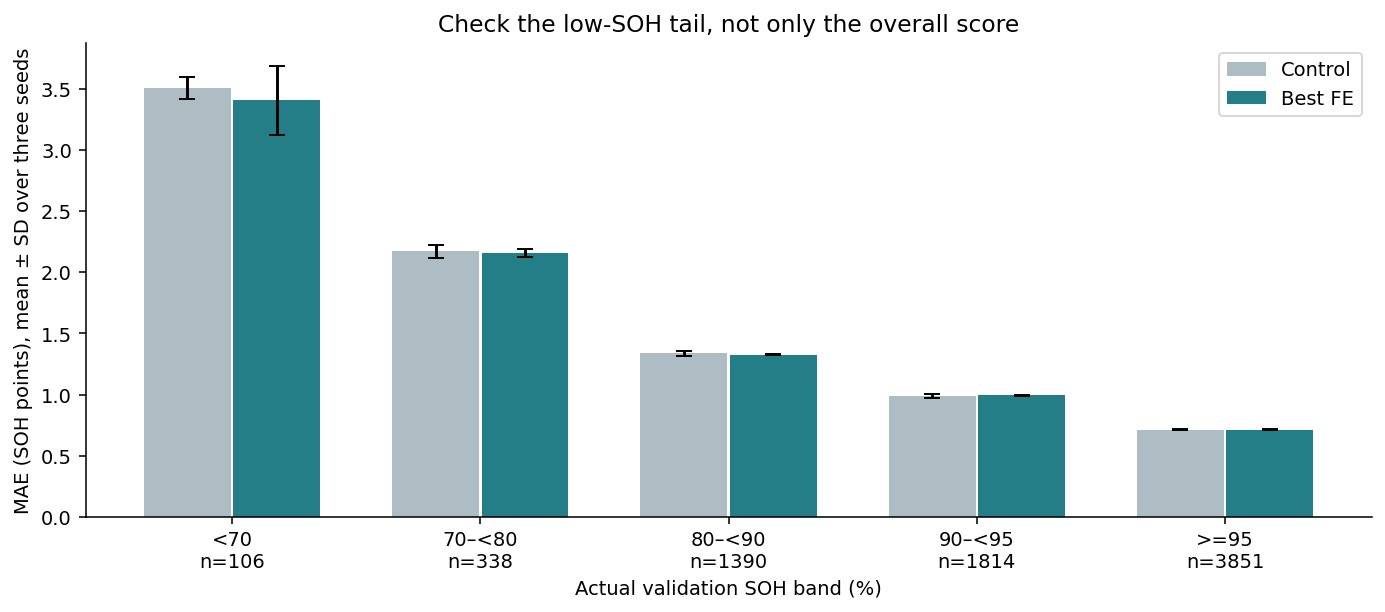

In [8]:
band_summary = pd.read_csv(output / "validation_band_summary.csv")
display(band_summary)
show("03_validation_tail_errors.png")
for variant, group in tables["validation_bands"].groupby("variant"):
    assert group.groupby("seed").rows.sum().eq(7499).all()

**Temuan:** pada SOH di bawah 70%, MAE turun dari sekitar **3,511 menjadi 3,411 poin** (106 observasi, 28 baterai), tetapi variasi antar-seed varian ini besar (SD 0,28). Rentang 90% sampai di bawah 95% justru sedikit memburuk. Karena jumlah datanya kecil, temuan ini tidak dipakai untuk mengubah aturan keputusan.

## 9. Keputusan

| Kriteria | Syarat | Hasil | Status |
|---|---|---|---|
| Gain rerata MAE | ≥ 0,01 poin | 0,00286 poin | Tidak lolos |
| Menang per seed | ≥ 2 dari 3 | 2 dari 3 | Lolos |

Jumlah parameter naik dari 553 menjadi 585 (+5,8%). Karena gain jauh di bawah ambang, **kandidat notebook 03 tanpa fitur turunan tetap menjadi model utama**. Varian konteks pengisian tetap dilaporkan sebagai hasil ablation.

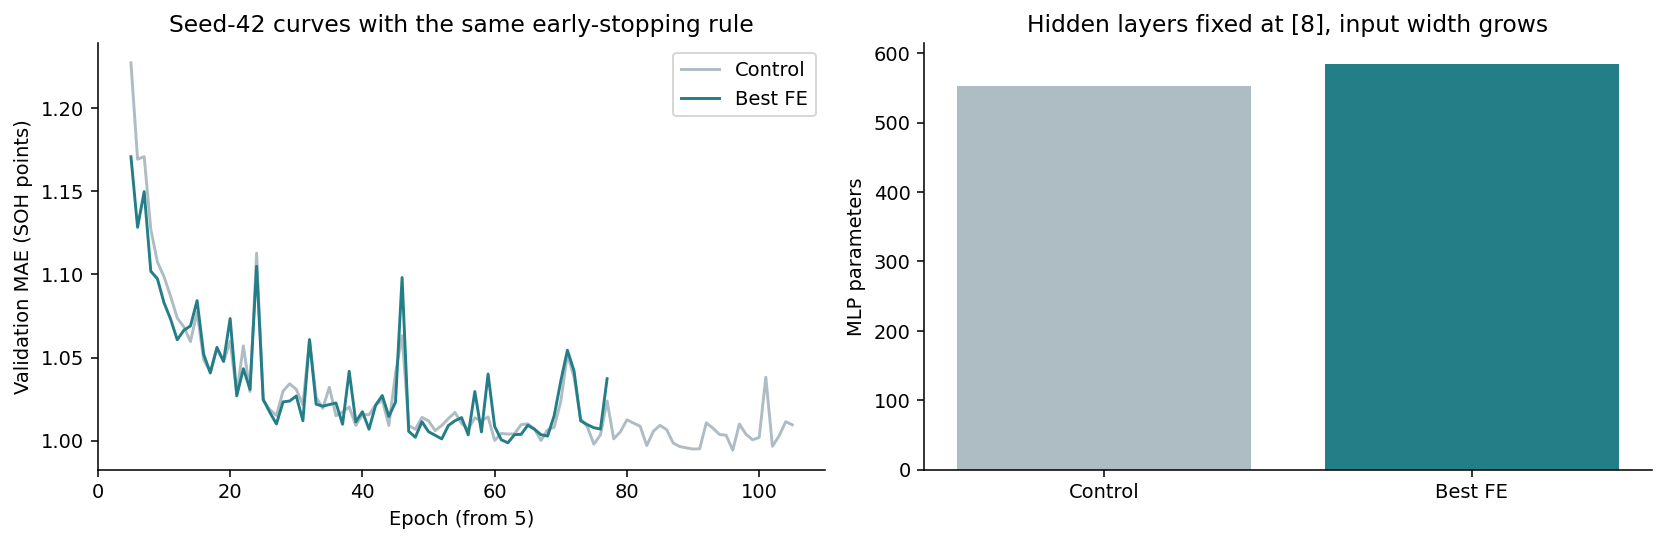

Rekomendasi: control_no_domain_features promosi: False


In [9]:
show("04_learning_and_complexity.png")
expected = (
    study["mean_validation_mae_improvement_pp"] >= settings["minimum_mean_mae_improvement_pp"]
    and study["seed_wins"] >= settings["minimum_seed_wins"]
)
assert expected == study["promoted_by_prespecified_gate"]
assert study["recommendation"] == "control_no_domain_features"
print("Rekomendasi:", study["recommendation"], "promosi:", study["promoted_by_prespecified_gate"])

## 10. Penyimpanan pipeline

Bundle inference berisi pipeline dasar, transformasi fitur tambahan, target scaler, dan nama fitur. Sel berikut memastikan fingerprint pipeline stabil setelah disimpan dan bobot MLP yang tersimpan mereproduksi validation MAE yang tercatat.

In [10]:
data = load_engineered_data(best, ROOT)
state = pipeline_state_fingerprint(data["bundle"]["preprocessor"], data["bundle"]["target_scaler"])
assert state == data["bundle"]["state_hash"]
run_id = tables["screening"].set_index("variant").loc[best, "run_id"]
metadata = json.loads(
    (ROOT / "results/experiments/runs" / run_id / "summary.json").read_text(encoding="utf-8")
)
model, _ = load_checkpoint(ROOT / metadata["checkpoint_best"], data)
pred = original_scale(model.predict(data["validation"]["X"]), data["bundle"])
mae = np.abs(pred - data["validation"]["y_original"]).mean()
assert np.isclose(mae, metadata["validation"]["mae"])
print("PASS: pipeline tersimpan dan checkpoint FE cocok serta mereproduksi validation MAE.")

PASS: pipeline tersimpan dan checkpoint FE cocok serta mereproduksi validation MAE.


## 11. Verifikasi

Unit test memeriksa rumus fitur, pembagian dengan nol, kimia baru, kesamaan 67 kolom kontrol, fit hanya pada train, dan serialisasi.

In [11]:
checked = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
    cwd=REPO,
    capture_output=True,
    text=True,
)
print(checked.stdout + checked.stderr)
assert checked.returncode == 0
assert (
    study["source_sha256"] == hashlib.sha256((REPO / "src/ev_battery/features.py").read_bytes()).hexdigest()
)
assert (
    study["settings_sha256"]
    == hashlib.sha256((ROOT / "configs/feature_engineering.json").read_bytes()).hexdigest()
)
assert not study["test_arrays_loaded"] and not study["test_transformed"]
assert len(report["figures"]) == 4
print("PASS: versi kode/config sesuai, tidak memakai test, seluruh pengujian lolos.")

START run_e00e66e3e4d3 probe conf=(1, 4, 1) sigmoid/mse gd lr=0.1 weighting=none seed=8
DONE run_e00e66e3e4d3: best epoch=6/6 (max_epoch), val MAE=4.0756, train MAE=4.0756, seconds=0.0
test_inference_never_calls_backward_or_fit (test_evaluation.FinalEvaluationTests.test_inference_never_calls_backward_or_fit) ... ok
test_lock_is_idempotent_but_refuses_changed_payload (test_evaluation.FinalEvaluationTests.test_lock_is_idempotent_but_refuses_changed_payload) ... ok
test_plan_rejects_seed_cherry_picking_or_fe_promotion (test_evaluation.FinalEvaluationTests.test_plan_rejects_seed_cherry_picking_or_fe_promotion) ... ok
test_subgroups_keep_sample_and_battery_denominators (test_evaluation.FinalEvaluationTests.test_subgroups_keep_sample_and_battery_denominators) ... ok
test_extra_fit_is_train_only_and_validation_transform_does_not_refit (test_features.FeatureEngineeringTests.test_extra_fit_is_train_only_and_validation_transform_does_not_refit) ... ok
test_fingerprint_detects_changed_learned_sca

## 12. Kesimpulan

- Pada data ini, fitur turunan tidak memberi perbaikan yang berarti. Varian terbaik hanya 0,00286 poin lebih baik secara rata-rata dan kalah di seed 42.
- Menambah lebih banyak fitur justru memperburuk hasil, karena jaringan kecil ([8]) harus mempelajari input yang lebih banyak tanpa informasi baru.
- Model utama tetap kandidat notebook 03.

Reproduksi dari root proyek:

```bash
python -m ev_battery features
python scripts/run_notebook.py notebooks/numpy/04_feature_engineering.ipynb
```

Artefak: `results/feature_engineering/FEATURE_ENGINEERING_REPORT.md`, tabel screening, konfirmasi seed, dan error per rentang SOH.

**Berikutnya:** `05_final_evaluation.ipynb` mereproduksi konfigurasi NumPy yang tercatat pada split test yang sudah dievaluasi sebelumnya.